<a href="https://colab.research.google.com/github/dreamer8848/Big-Data-Analytics/blob/main/Data_Visualisation_Big_Data_week_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
cd /content/drive/MyDrive/Colab Notebooks/Big Data

/content/drive/MyDrive/Colab Notebooks/Big Data


In [ ]:
# 1. Import libraries:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# The warnings module in Python provides a way to control how warnings are handled within a Python script. It allows developers to emit warning messages to alert users of potential issues or unexpected behaviour in their code.
import warnings
warnings.filterwarnings('ignore')
sns.set(color_codes = True)
sns.set_palette(palette = 'magma', n_colors = 8)

In [ ]:
# 2. Import dataset:
import os
import pandas as pd

file_name = 'Impact_music_mental_health.csv'
if os.path.exists(file_name):
    df = pd.read_csv(file_name)
    print("Dataset imported successfully!")
    print(df.head())
else:
    print(f"Please ensure '{file_name}' exists in: {os.getcwd()}")

Dataset imported successfully!
            Timestamp   Age Primary streaming service  Hours per day  \
0  8/27/2022 19:29:02  18.0                   Spotify            3.0   
1  8/27/2022 19:57:31  63.0                   Pandora            1.5   
2  8/27/2022 21:28:18  18.0                   Spotify            4.0   
3  8/27/2022 21:40:40  61.0             YouTube Music            2.5   
4  8/27/2022 21:54:47  18.0                   Spotify            4.0   

  While working Instrumentalist Composer         Fav genre Exploratory  \
0           Yes             Yes      Yes             Latin         Yes   
1           Yes              No       No              Rock         Yes   
2            No              No       No  Video game music          No   
3           Yes              No      Yes              Jazz         Yes   
4           Yes              No       No               R&B         Yes   

  Foreign languages  ...  Frequency [R&B]  Frequency [Rap] Frequency [Rock]  \
0           

In [ ]:
# 3. Check dataset:
data.shape
data.info()
data.describe().T
data.describe(exclude='number').T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 736 entries, 0 to 735
Data columns (total 33 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Timestamp                     736 non-null    object 
 1   Age                           735 non-null    float64
 2   Primary streaming service     735 non-null    object 
 3   Hours per day                 736 non-null    float64
 4   While working                 733 non-null    object 
 5   Instrumentalist               732 non-null    object 
 6   Composer                      735 non-null    object 
 7   Fav genre                     736 non-null    object 
 8   Exploratory                   736 non-null    object 
 9   Foreign languages             732 non-null    object 
 10  BPM                           629 non-null    float64
 11  Frequency [Classical]         736 non-null    object 
 12  Frequency [Country]           736 non-null    object 
 13  Frequ

,count,unique,top,freq
Timestamp,736,729,09/01/2022 15:24,2
Primary streaming service,735,6,Spotify,458
While working,733,2,Yes,579
Instrumentalist,732,2,No,497
Composer,735,2,No,609
Fav genre,736,16,Rock,188
Exploratory,736,2,Yes,525
Foreign languages,732,2,Yes,404
Frequency [Classical],736,4,Rarely,259
Frequency [Country],736,4,Never,343


In [ ]:
# 4. Remove outliers:
age_index = data[(data['Age'] > 70)].index
data = data.drop(age_index, axis=0)
hpd_index = data[data['Hours per day'] >= 15].index
data = data.drop(hpd_index, axis=0)
data_index = data[data['BPM'] > 200].index
data = data.drop(data_index, axis=0)
#Removing not-needed column:
data.drop(['Timestamp', 'Permissions'], axis=1, inplace=True)

In [ ]:
# Display shape and first few rows of the cleaned dataset
print("Cleaned dataset shape:", data.shape)
display(data.head())

Cleaned dataset shape: (714, 31)


,Age,Primary streaming service,Hours per day,While working,Instrumentalist,Composer,Fav genre,Exploratory,Foreign languages,BPM,...,Frequency [Pop],Frequency [R&B],Frequency [Rap],Frequency [Rock],Frequency [Video game music],Anxiety,Depression,Insomnia,OCD,Music effects
0,18.0,Spotify,3.0,Yes,Yes,Yes,Latin,Yes,Yes,156.0,...,Very frequently,Sometimes,Very frequently,Never,Sometimes,3.0,0.0,1.0,0.0,NaN
1,63.0,Pandora,1.5,Yes,No,No,Rock,Yes,No,119.0,...,Sometimes,Sometimes,Rarely,Very frequently,Rarely,7.0,2.0,2.0,1.0,NaN
2,18.0,Spotify,4.0,No,No,No,Video game music,No,Yes,132.0,...,Rarely,Never,Rarely,Rarely,Very frequently,7.0,7.0,10.0,2.0,No effect
3,61.0,YouTube Music,2.5,Yes,No,Yes,Jazz,Yes,Yes,84.0,...,Sometimes,Sometimes,Never,Never,Never,9.0,7.0,3.0,3.0,Improve
4,18.0,Spotify,4.0,Yes,No,No,R&B,Yes,No,107.0,...,Sometimes,Very frequently,Very frequently,Never,Rarely,7.0,2.0,5.0,9.0,Improve


Anxiety         -0.147222
OCD             -0.123097
Hours per day   -0.098354
Depression      -0.087602
BPM             -0.019868
Insomnia         0.039365
Age              1.000000
Name: Age, dtype: float64


<Axes: >

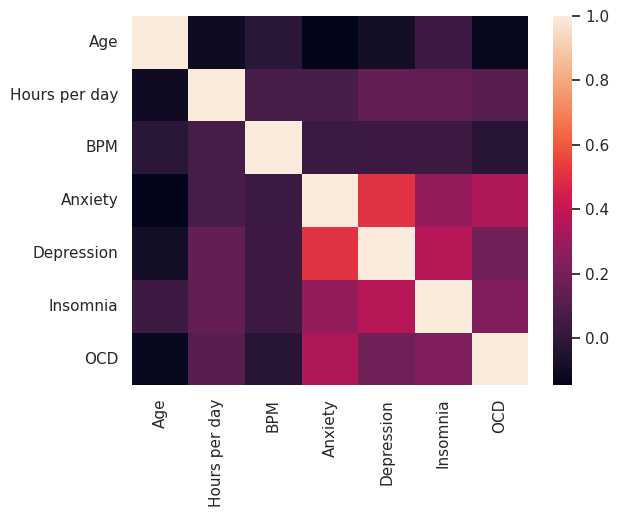

In [ ]:
#5. Correlation check:
corr_data = data.corr(numeric_only=True)['Age']
print(corr_data.sort_values())
sns.heatmap(data.corr(numeric_only=True))

In [ ]:
data.isnull().sum()

,0
Age,1
Primary streaming service,1
Hours per day,0
While working,3
Instrumentalist,4
Composer,1
Fav genre,0
Exploratory,0
Foreign languages,4
BPM,105


In [ ]:
data['Age'] = data['Age'].fillna(round(data['Age'].mean(), 0))
data['Primary streaming service'] = data['Primary streaming service'].fillna(data['Primary streaming service'].mode()[0])
data['While working'] = data['While working'].fillna(data['While working'].mode()[0])
data['Instrumentalist'] = data['Instrumentalist'].fillna(data['Instrumentalist'].mode()[0])
data['Composer'] = data['Composer'].fillna(data['Composer'].mode()[0])
data['Foreign languages'] = data['Foreign languages'].fillna(data['Foreign languages'].mode()[0])
data['Music effects'] = data['Music effects'].fillna(data['Music effects'].mode()[0])

miss_bpm = data[data['BPM'].isnull() == True]
miss_bpm_genre = ['Country', 'Hip hop', 'Pop', 'Rock', 'Metal', 'Classical', 'Video game music', 'R&B', 'Folk', 'Jazz', 'EDM', 'Gospel', 'K pop', 'Rap']

for i in miss_bpm_genre:
    data['BPM'] = data['BPM'].fillna(round(data[data['Fav genre'] == i]['BPM'].mean(), 0))

In [ ]:
# Verify if there are any remaining missing values
data.isnull().sum()

,0
Age,0
Primary streaming service,0
Hours per day,0
While working,0
Instrumentalist,0
Composer,0
Fav genre,0
Exploratory,0
Foreign languages,0
BPM,0


In [ ]:
display(data.head())

,Age,Primary streaming service,Hours per day,While working,Instrumentalist,Composer,Fav genre,Exploratory,Foreign languages,BPM,...,Frequency [Pop],Frequency [R&B],Frequency [Rap],Frequency [Rock],Frequency [Video game music],Anxiety,Depression,Insomnia,OCD,Music effects
0,18.0,Spotify,3.0,Yes,Yes,Yes,Latin,Yes,Yes,156.0,...,Very frequently,Sometimes,Very frequently,Never,Sometimes,3.0,0.0,1.0,0.0,Improve
1,63.0,Pandora,1.5,Yes,No,No,Rock,Yes,No,119.0,...,Sometimes,Sometimes,Rarely,Very frequently,Rarely,7.0,2.0,2.0,1.0,Improve
2,18.0,Spotify,4.0,No,No,No,Video game music,No,Yes,132.0,...,Rarely,Never,Rarely,Rarely,Very frequently,7.0,7.0,10.0,2.0,No effect
3,61.0,YouTube Music,2.5,Yes,No,Yes,Jazz,Yes,Yes,84.0,...,Sometimes,Sometimes,Never,Never,Never,9.0,7.0,3.0,3.0,Improve
4,18.0,Spotify,4.0,Yes,No,No,R&B,Yes,No,107.0,...,Sometimes,Very frequently,Very frequently,Never,Rarely,7.0,2.0,5.0,9.0,Improve


In [ ]:
#7. Data check and copy:
data.shape
df = data.copy()

Text(0.5, 0, 'EDM Music')

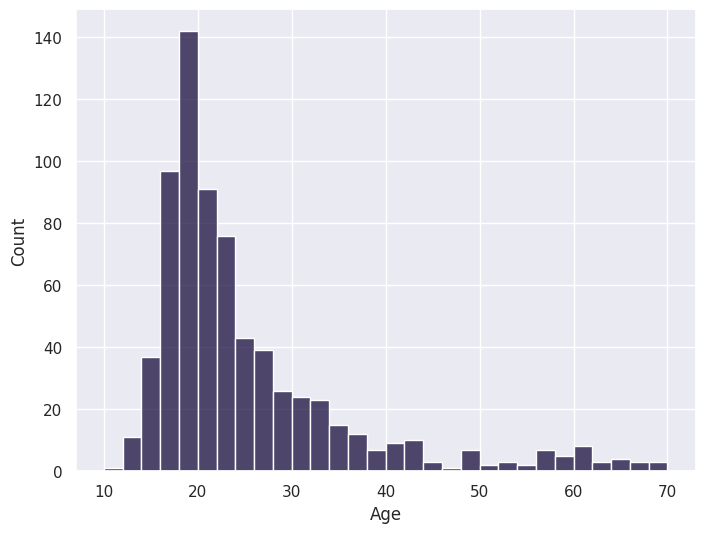

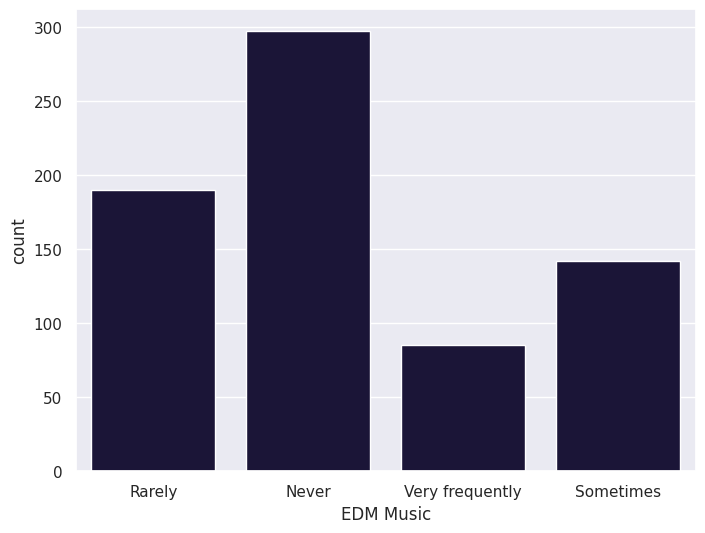

In [ ]:
# Data visualization (continue with other parameters):
plt.figure(figsize=(8,6))
sns.histplot(data['Age'])
plt.figure(figsize=(8,6))
sns.countplot(x=data['Frequency [EDM]'])
plt.xlabel('EDM Music')

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15],
 [Text(0, 0, 'Latin'),
  Text(1, 0, 'Rock'),
  Text(2, 0, 'Video game music'),
  Text(3, 0, 'Jazz'),
  Text(4, 0, 'R&B'),
  Text(5, 0, 'K pop'),
  Text(6, 0, 'Country'),
  Text(7, 0, 'EDM'),
  Text(8, 0, 'Hip hop'),
  Text(9, 0, 'Pop'),
  Text(10, 0, 'Rap'),
  Text(11, 0, 'Classical'),
  Text(12, 0, 'Metal'),
  Text(13, 0, 'Folk'),
  Text(14, 0, 'Lofi'),
  Text(15, 0, 'Gospel')])

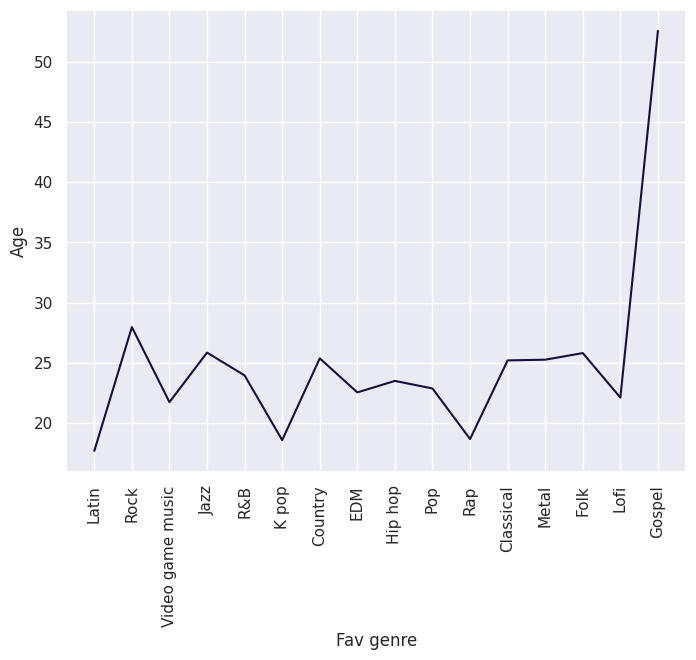

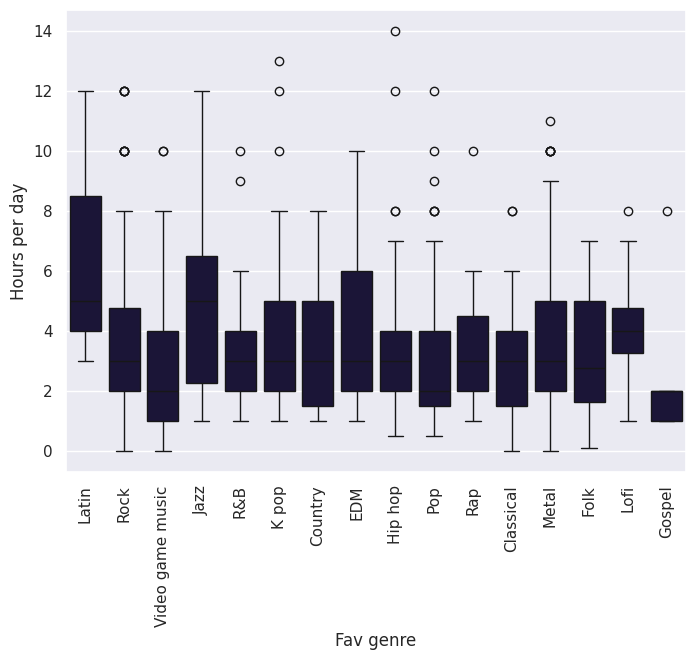

In [ ]:
#9. Bivariate analysis:
plt.figure(figsize=(8,6))
sns.lineplot(x=data['Fav genre'], y=data['Age'], ci=None)
plt.xticks(rotation=90)
plt.figure(figsize=(8,6))
sns.boxplot(x=data['Fav genre'], y=data['Hours per day'])
plt.xticks(rotation=90)

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15],
 [Text(0, 0, 'Latin'),
  Text(1, 0, 'Rock'),
  Text(2, 0, 'Video game music'),
  Text(3, 0, 'Jazz'),
  Text(4, 0, 'R&B'),
  Text(5, 0, 'K pop'),
  Text(6, 0, 'Country'),
  Text(7, 0, 'EDM'),
  Text(8, 0, 'Hip hop'),
  Text(9, 0, 'Pop'),
  Text(10, 0, 'Rap'),
  Text(11, 0, 'Classical'),
  Text(12, 0, 'Metal'),
  Text(13, 0, 'Folk'),
  Text(14, 0, 'Lofi'),
  Text(15, 0, 'Gospel')])

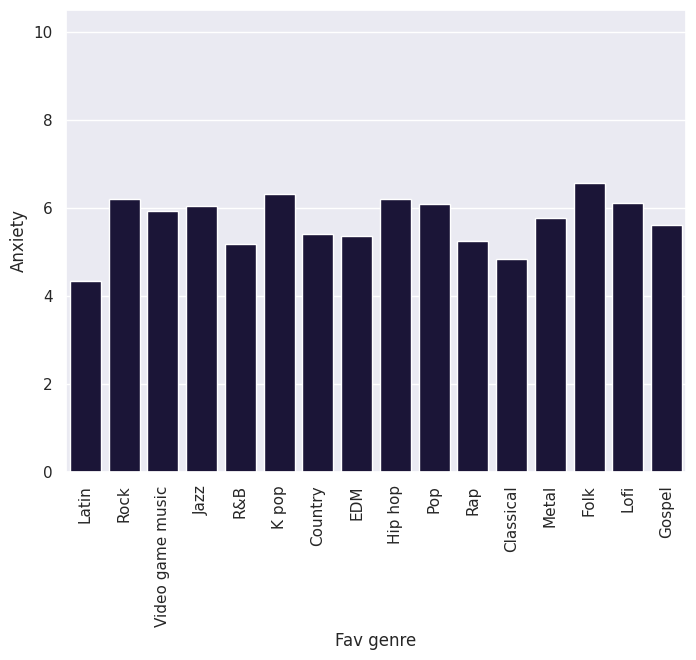

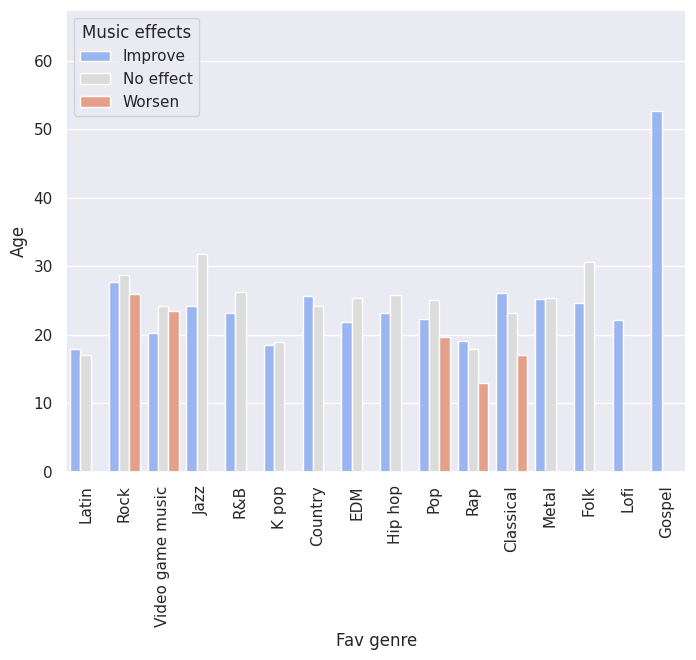

In [ ]:
#10. Bar plot:
plt.figure(figsize=(8,6))
sns.barplot(x=data['Fav genre'], y=data['Anxiety'], errwidth=0)
plt.xticks(rotation=90)
plt.figure(figsize=(8,6))
sns.barplot(x=data['Fav genre'], y=data['Age'], hue=data['Music effects'], errwidth=0, palette='coolwarm')
plt.xticks(rotation=90)

### 11. Additional Advanced Visualizations
Let's generate a Joint Kernel Density Estimate (KDE) plot to see the concentration of Anxiety vs. Depression scores, and a Genre vs. Mental Health Rating Heatmap.

<Figure size 800x600 with 0 Axes>

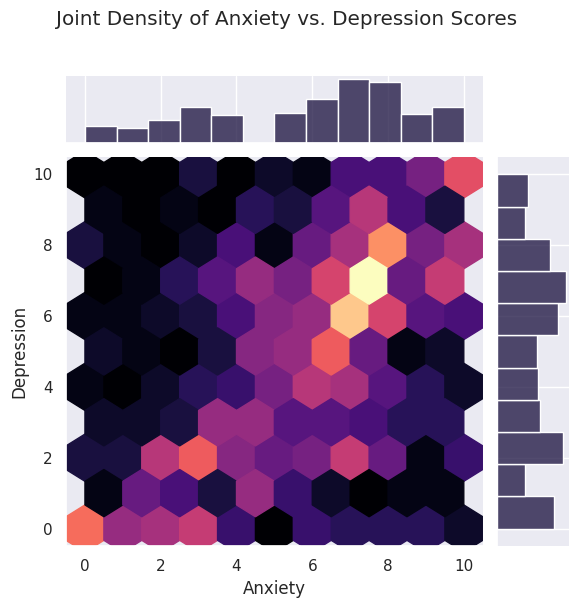

In [ ]:
# A. Joint Plot showing the density overlay of Anxiety and Depression scores
plt.figure(figsize=(8,6))
sns.jointplot(data=data, x='Anxiety', y='Depression', kind='hex', cmap='magma')
plt.subplots_adjust(top=0.9)
plt.gcf().suptitle('Joint Density of Anxiety vs. Depression Scores', y=1.01)
plt.show()

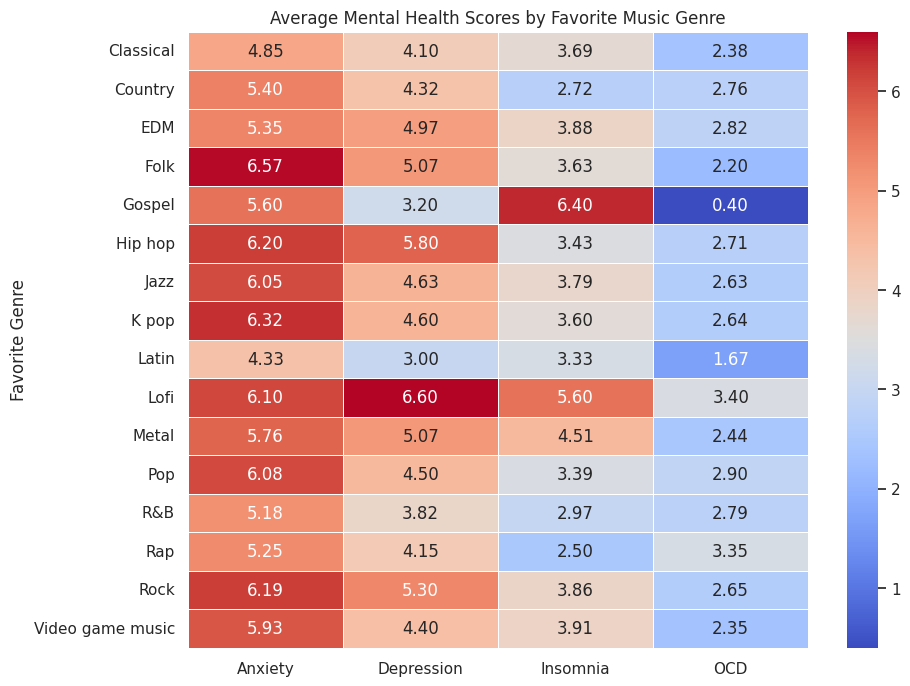

In [ ]:
# B. Heatmap of average mental health scores (Anxiety, Depression, Insomnia, OCD) across different Favorite Genres
mental_cols = ['Anxiety', 'Depression', 'Insomnia', 'OCD']
genre_mental_summary = data.groupby('Fav genre')[mental_cols].mean()

plt.figure(figsize=(10, 8))
sns.heatmap(genre_mental_summary, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Average Mental Health Scores by Favorite Music Genre')
plt.ylabel('Favorite Genre')
plt.show()

### 12. Correlation of Listening Volume (`Hours per day`) to Mental Health
Let's check if there is a trend between how many hours a day a respondent listens to music and their reported Anxiety or Depression levels.

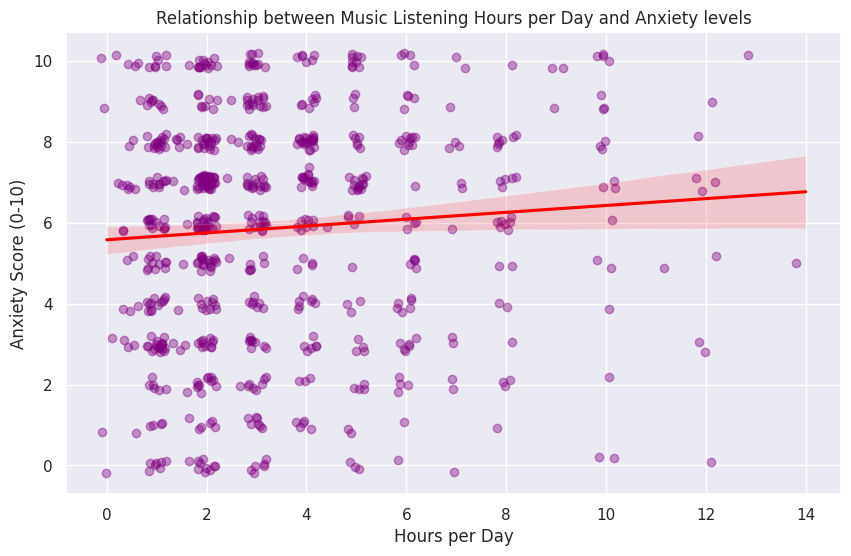

In [ ]:
# A. Regression plot exploring Hours per Day vs. Anxiety
plt.figure(figsize=(10, 6))
sns.regplot(data=data, x='Hours per day', y='Anxiety', x_jitter=0.2, y_jitter=0.2,
            scatter_kws={'alpha':0.4, 'color':'purple'}, line_kws={'color':'red'})
plt.title('Relationship between Music Listening Hours per Day and Anxiety levels')
plt.xlabel('Hours per Day')
plt.ylabel('Anxiety Score (0-10)')
plt.show()

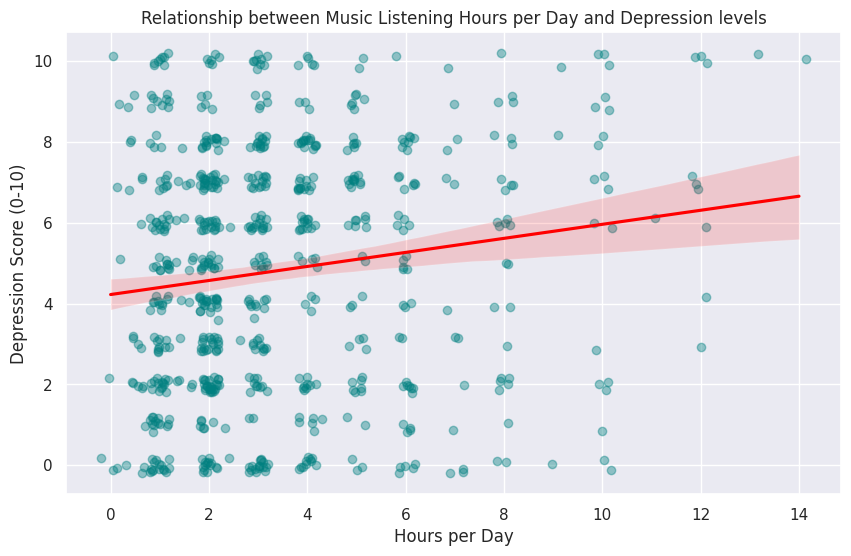

In [ ]:
# B. Regression plot exploring Hours per Day vs. Depression
plt.figure(figsize=(10, 6))
sns.regplot(data=data, x='Hours per day', y='Depression', x_jitter=0.2, y_jitter=0.2,
            scatter_kws={'alpha':0.4, 'color':'teal'}, line_kws={'color':'red'})
plt.title('Relationship between Music Listening Hours per Day and Depression levels')
plt.xlabel('Hours per Day')
plt.ylabel('Depression Score (0-10)')
plt.show()

### 13. Comparing Mental Health Scores by Working Habit (`While working`)
Let's check if listening to music while working or studying correlates with differing levels of Anxiety and Depression using violin plots.

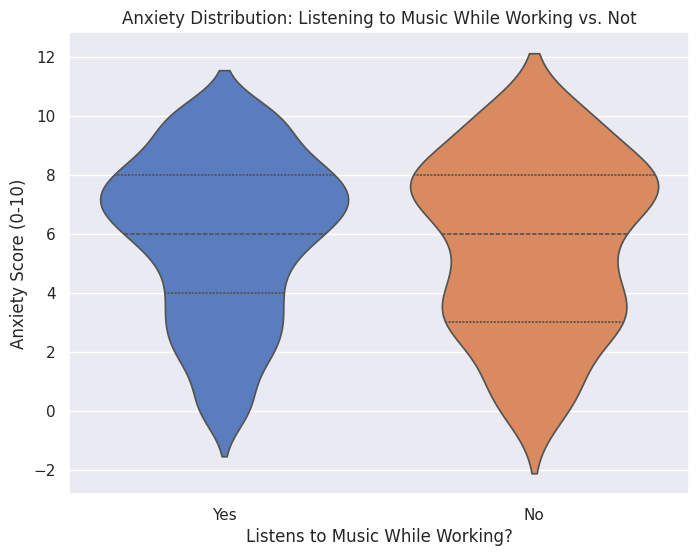

In [ ]:
# A. Violin plot comparing Anxiety scores split by 'While working'
plt.figure(figsize=(8,6))
sns.violinplot(data=data, x='While working', y='Anxiety', palette='muted', inner='quartile')
plt.title('Anxiety Distribution: Listening to Music While Working vs. Not')
plt.xlabel('Listens to Music While Working?')
plt.ylabel('Anxiety Score (0-10)')
plt.show()

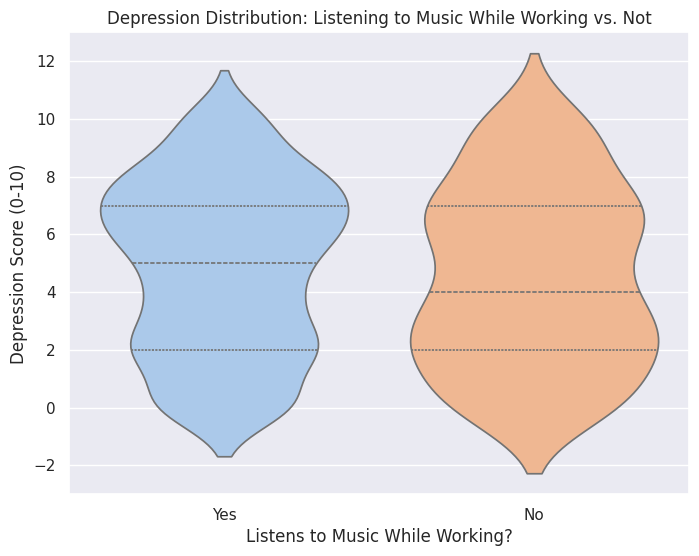

In [ ]:
# B. Violin plot comparing Depression scores split by 'While working'
plt.figure(figsize=(8,6))
sns.violinplot(data=data, x='While working', y='Depression', palette='pastel', inner='quartile')
plt.title('Depression Distribution: Listening to Music While Working vs. Not')
plt.xlabel('Listens to Music While Working?')
plt.ylabel('Depression Score (0-10)')
plt.show()

### 14. Age Distribution Across Different Music Genres
Let's look at the age demographics for each favorite music genre using a box plot to see which genres attract younger vs. older listeners.

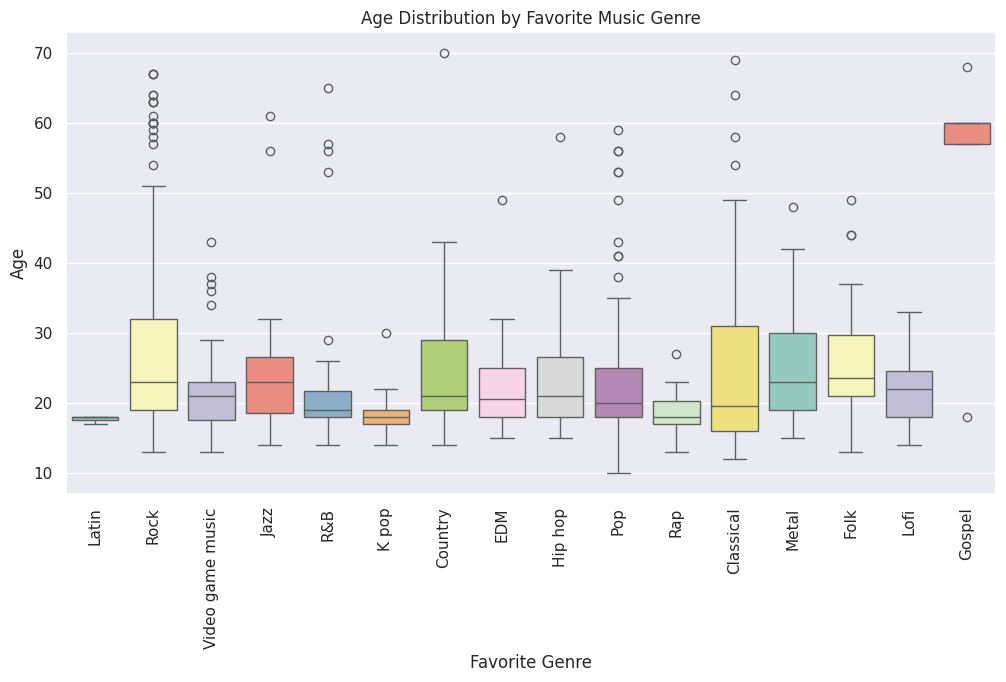

In [ ]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=data, x='Fav genre', y='Age', palette='Set3')
plt.xticks(rotation=90)
plt.title('Age Distribution by Favorite Music Genre')
plt.xlabel('Favorite Genre')
plt.ylabel('Age')
plt.show()